In [4]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
world = gpd.read_file("data/naturalearth_lowres/naturalearth_lowres.shp")

In [ ]:
asia = world[world["continent"] == "Asia"].copy()

In [32]:
df = pd.read_csv(
    "API_IT.NET.USER.ZS_DS2_en_csv_v2_62387/API_IT.NET.USER.ZS_DS2_en_csv_v2_62387.csv",
    skiprows=4
)
df.columns

Index(['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code',
       '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022',
       '2023', '2024', '2025', 'Unnamed: 70'],
      dtype='str')

In [33]:
print(df["2024"].notna().sum()) # look at the most recent year that has a lot of data


214


In [41]:
internet = df[["Country Code", "2024"]]

In [42]:
internet.head()

,Country Code,2024
0,ABW,NaN
1,AFE,28.800000
2,AFG,16.094999
3,AFW,40.000000
4,AGO,40.704800


In [59]:
internet = internet.rename(columns={"Country Code": "iso_a3", "2024": "internet_users_pct"})

In [62]:
asia = asia.merge(internet, on="iso_a3", how="left")
asia.head()

,pop_est,continent,name,iso_a3,gdp_md_est,geometry,internet_users_pct
0,18513930.0,Asia,Kazakhstan,KAZ,181665,"POLYGON ((87.35997 49.21498, 86.59878 48.54918...",93.391673
1,33580650.0,Asia,Uzbekistan,UZB,57921,"POLYGON ((55.96819 41.30864, 55.92892 44.99586...",89.505501
2,270625568.0,Asia,Indonesia,IDN,1119190,"MULTIPOLYGON (((141.00021 -2.60015, 141.01706 ...",72.780755
3,1293119.0,Asia,Timor-Leste,TLS,2017,"POLYGON ((124.96868 -8.89279, 125.08625 -8.656...",NaN
4,9053300.0,Asia,Israel,ISR,394652,"POLYGON ((35.71992 32.70919, 35.54567 32.39399...",88.182422


In [63]:
asia[asia["internet_users_pct"].isna()]

,pop_est,continent,name,iso_a3,gdp_md_est,geometry,internet_users_pct
3,1293119.0,Asia,Timor-Leste,TLS,2017,"POLYGON ((124.96868 -8.89279, 125.08625 -8.656...",NaN
6,4685306.0,Asia,Palestine,PSE,16276,"POLYGON ((35.39756 31.48909, 34.92741 31.35344...",NaN
16,54045420.0,Asia,Myanmar,MMR,76085,"POLYGON ((100.11599 20.41785, 99.54331 20.1866...",NaN
18,25666161.0,Asia,North Korea,PRK,40000,"MULTIPOLYGON (((130.78 42.22001, 130.78 42.220...",NaN
29,5942089.0,Asia,Turkmenistan,TKM,40761,"POLYGON ((52.50246 41.78332, 52.94429 42.11603...",NaN
31,17070135.0,Asia,Syria,SYR,98830,"POLYGON ((35.71992 32.70919, 35.7008 32.71601,...",NaN
36,23568378.0,Asia,Taiwan,TWN,1127000,"POLYGON ((121.77782 24.39427, 121.17563 22.790...",NaN
43,29161922.0,Asia,Yemen,YEM,22581,"POLYGON ((52.00001 19, 52.78218 17.34974, 53.1...",NaN
45,326000.0,Asia,N. Cyprus,CYN,3600,"POLYGON ((32.73178 35.14003, 32.80247 35.1455,...",NaN


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

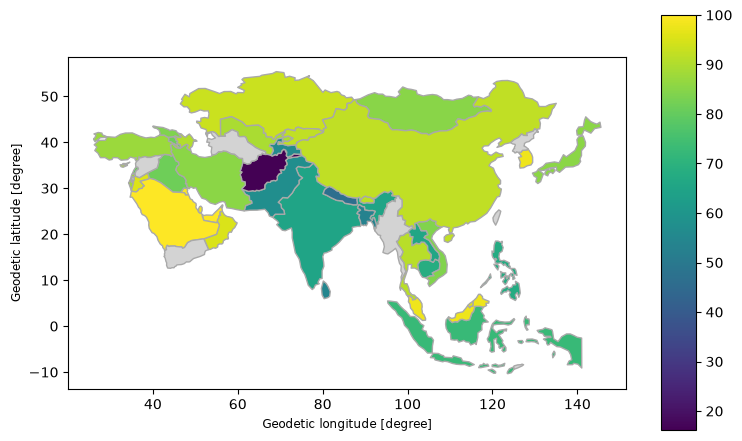

In [81]:
fig, ax = plt.subplots(figsize=(9,9))
asia.plot(
    column="internet_users_pct",
    ax=ax,
    legend=True,
    missing_kwds={"color": "lightgrey"},
    edgecolor= "darkgrey"
)